After learning [forward propagation](../forward-propagation/index.qmd), I want intuition for how the three main architecture choices change what a network computes:

- the **number of hidden layers** (depth),
- the **number of nodes per layer** (width),
- the **activation function**.

These interact, so the study changes **one factor at a time** and holds everything else fixed, like a controlled experiment.

## The experimental design

**Keep the output visible.** Every network has **one input** $x \in [-3, 3]$ and **one output** $\hat{y}$, so each network is a curve I can look at directly. The output layer is linear (no activation), as in regression.

**One baseline, one change at a time.**

| Experiment | Depth (hidden layers) | Width (nodes / layer) | Activation |
|---|---|---|---|
| Baseline | 2 | 8 | tanh |
| Depth sweep | **1, 2, 4, 8** | 8 | tanh (and ReLU) |
| Width sweep | 2 | **2, 4, 8, 32** | tanh (and ReLU) |
| Activation sweep | 2 | 8 | **linear, sigmoid, tanh, ReLU, Leaky ReLU, GELU** |
| Fixed parameter budget | **1 × 48, 2 × 10, 4 × 6** (≈ 145 parameters each) | | ReLU |

The depth and width sweeps are run with both tanh (smooth) and ReLU (piecewise linear), because the two families respond differently.

**Things that could quietly spoil the comparison, and how I control them:**

1. **Weight scale.** Careless random weights make deep tanh networks saturate and deep ReLU networks blow up, and then "deeper" really means "badly scaled". So every network uses the standard **scale-preserving initialization**: $W_{jk} \sim \mathcal{N}(0,\; g/n_{\text{in}})$, with gain $g = 1$ for linear/sigmoid/tanh (LeCun/Xavier-style) and $g = 2$ for ReLU/Leaky ReLU/GELU (He-style). Biases are $b_j \sim \mathcal{N}(0, 0.5^2)$.
2. **Different random draws.** A network's weights are $\sqrt{g/n_{\text{in}}}\, Z$, where the standard-normal matrices $Z$ come from a fixed seed. In the activation sweep every network uses **the same $Z$**, so the activation (and its gain) is the only difference.
3. **Luck of one draw.** Each setting is shown for several seeds, and the summary numbers are averaged over 30 seeds (untrained) or reported as the median over 6 seeds (trained).
4. **Parameter count.** Going deeper also adds parameters. The fixed-budget experiment compares shapes with (almost) the same number of parameters.
5. **Training settings** (part B). The data, loss, optimizer, learning rate, and number of steps are identical for every network.

**What I measure:**

- **turning points:** how often the curve *visibly* changes direction (a "wiggliness" count);
- **output spread:** the standard deviation of $\hat{y}$ over $x$, i.e. how much the output actually varies;
- **linear pieces** (ReLU-family only): a ReLU network's output is piecewise linear, and I count its pieces by tracking where any hidden node switches on or off;
- **train / test error** (part B): mean squared error on the training points and against the true curve.

The study has two parts:

- **Part A — untrained networks:** forward propagation only, with random weights. This shows what *kind* of function each architecture produces before any learning.
- **Part B — trained networks:** the same networks, trained to fit one target curve. This shows what each architecture can *actually learn*.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

X = np.linspace(-3, 3, 2001)                  # where we look at each network's curve
SEED_COLORS = plt.cm.tab10.colors

## The network, from scratch

A network with depth $D$ and width $n$ has layer sizes $[1, n, \dots, n, 1]$. Forward propagation is exactly the recursion from the forward-propagation note — a linear map, then an element-wise activation, repeated — with a linear output layer:

$$
\mathbf{h}^{(0)} = x, \qquad
\mathbf{a}^{(l)} = W^{(l)}\mathbf{h}^{(l-1)} + \mathbf{b}^{(l)}, \qquad
\mathbf{h}^{(l)} = f\big(\mathbf{a}^{(l)}\big)\;\; (l \le D), \qquad
\hat{y} = \mathbf{a}^{(D+1)}.
$$

In code I process all $x$ values at once, one per **row**, so the per-sample $W\mathbf{h} + \mathbf{b}$ becomes `H @ W.T + b`.

In [2]:
_erf = np.vectorize(math.erf)
def _sig(z):  return 1.0 / (1.0 + np.exp(-z))
def _Phi(z):  return 0.5 * (1.0 + _erf(z / np.sqrt(2.0)))       # standard normal CDF
def _phi(z):  return np.exp(-0.5 * z**2) / np.sqrt(2.0 * np.pi)  # standard normal density

# name -> (f, f', init gain g).  g = 1: LeCun/Xavier-style,  g = 2: He-style.
ACT = {
    "linear":     (lambda z: z,                            lambda z: np.ones_like(z),           1.0),
    "sigmoid":    (_sig,                                   lambda z: _sig(z) * (1 - _sig(z)),   1.0),
    "tanh":       (np.tanh,                                lambda z: 1 - np.tanh(z) ** 2,       1.0),
    "relu":       (lambda z: np.maximum(0, z),             lambda z: (z > 0).astype(float),     2.0),
    "leaky_relu": (lambda z: np.where(z > 0, z, 0.1 * z),  lambda z: np.where(z > 0, 1.0, 0.1), 2.0),
    "gelu":       (lambda z: z * _Phi(z),                  lambda z: _Phi(z) + z * _phi(z),     2.0),
}
NICE = {"linear": "Linear", "sigmoid": "Sigmoid", "tanh": "Tanh", "relu": "ReLU",
        "leaky_relu": "Leaky ReLU", "gelu": "GELU"}

def init_params(depth, width, act, seed, sigma_b=0.5):
    """Layer sizes [1, width x depth, 1].  W = sqrt(g / n_in) * Z with Z ~ N(0, 1) from `seed`,
    b ~ N(0, sigma_b^2).  The same (depth, width, seed) always draws the same Z, whatever `act`.
    The output layer is linear, so it always uses g = 1."""
    sizes = [1] + [width] * depth + [1]
    rng = np.random.default_rng(seed)
    gain = ACT[act][2]
    params = []
    for l, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
        Z = rng.standard_normal((n_out, n_in))
        g = gain if l < len(sizes) - 2 else 1.0
        params.append([np.sqrt(g / n_in) * Z, sigma_b * rng.standard_normal(n_out)])
    return params

def n_params(depth, width):
    return sum(W.size + b.size for W, b in init_params(depth, width, "tanh", 0))

def forward(params, x, act):
    """a = H W^T + b, h = f(a) for hidden layers; the last layer is linear.
    Returns y_hat and the cache [(a, h), ...] needed by backprop and by count_pieces."""
    f = ACT[act][0]
    h = x[:, None]
    cache = [(None, h)]
    for l, (W, b) in enumerate(params):
        a = h @ W.T + b
        h = f(a) if l < len(params) - 1 else a
        cache.append((a, h))
    return h[:, 0], cache

### The measurements

- **Turning points** count changes of direction that you could actually see: a turn only counts once the curve has moved back by more than **5% of its total range**. (Counting every sign change of the slope would also count microscopic wiggles that don't show up in any plot.)
- **Linear pieces** (ReLU-family only): within one piece, every hidden node stays on the same side of 0. So I record the on/off pattern of all hidden nodes at 20,001 points, and every place the pattern changes starts a new piece. (A pattern change creates a kink in the curve, though occasionally a very slight one.)

In [3]:
def turning_points(y, frac=0.05):
    """Count visible changes of direction: a reversal counts only once the curve has moved
    back by more than `frac` of its total range (max - min)."""
    thr = frac * (y.max() - y.min())
    if thr == 0:
        return 0
    hi = lo = y[0]
    direction, turns = 0, 0                    # direction: +1 rising, -1 falling, 0 undecided
    for v in y[1:]:
        if direction == 0:
            hi, lo = max(hi, v), min(lo, v)
            if hi - y[0] > thr and v == hi:
                direction = 1
            elif y[0] - lo > thr and v == lo:
                direction = -1
        elif direction == 1:
            if v > hi:
                hi = v
            elif hi - v > thr:
                turns, direction, lo = turns + 1, -1, v
        else:
            if v < lo:
                lo = v
            elif v - lo > thr:
                turns, direction, hi = turns + 1, 1, v
    return turns

def count_pieces(params, act, n=20001):
    xs = np.linspace(-3, 3, n)
    _, cache = forward(params, xs, act)
    pattern = np.concatenate([a > 0 for a, _ in cache[1:-1]], axis=1)   # on/off of every hidden node
    return int(np.any(pattern[1:] != pattern[:-1], axis=1).sum()) + 1

def summarize(depth, width, act, n_seeds=30):
    """Average the measurements over many random networks of one architecture."""
    turns, spread, pieces = [], [], []
    for s in range(n_seeds):
        p = init_params(depth, width, act, s)
        y, _ = forward(p, X, act)
        turns.append(turning_points(y)); spread.append(y.std())
        if act in ("relu", "leaky_relu"):
            pieces.append(count_pieces(p, act))
    return dict(turns=np.mean(turns), spread=np.mean(spread),
                pieces=np.mean(pieces) if pieces else None)

def untrained_panel(ax, depth, width, act, title, n_show=5):
    """Overlay n_show random networks of one architecture; title carries the 30-seed averages."""
    for s in range(n_show):
        y, _ = forward(init_params(depth, width, act, s), X, act)
        ax.plot(X, y, color=SEED_COLORS[s], lw=1.4)
    st = summarize(depth, width, act)
    stats = f"turns {st['turns']:.1f} · spread {st['spread']:.2f}"
    if st["pieces"] is not None:
        stats = f"pieces {st['pieces']:.0f} · " + stats
    ax.set_title(f"{title}\n{stats}", fontsize=10)
    ax.axhline(0, color="0.85", lw=0.8, zorder=0)
    ax.set_xlim(-3, 3)
    return st

# Part A — untrained networks

Each panel overlays **5 random networks** (seeds 0–4, the same color = the same seed $Z$ across panels where the shapes allow it). The panel title gives averages over **30** random networks. Every panel has its **own y-scale**, so compare *shapes* across panels and read the size from "spread".

## A1. Depth: 1, 2, 4, 8 hidden layers (width 8)

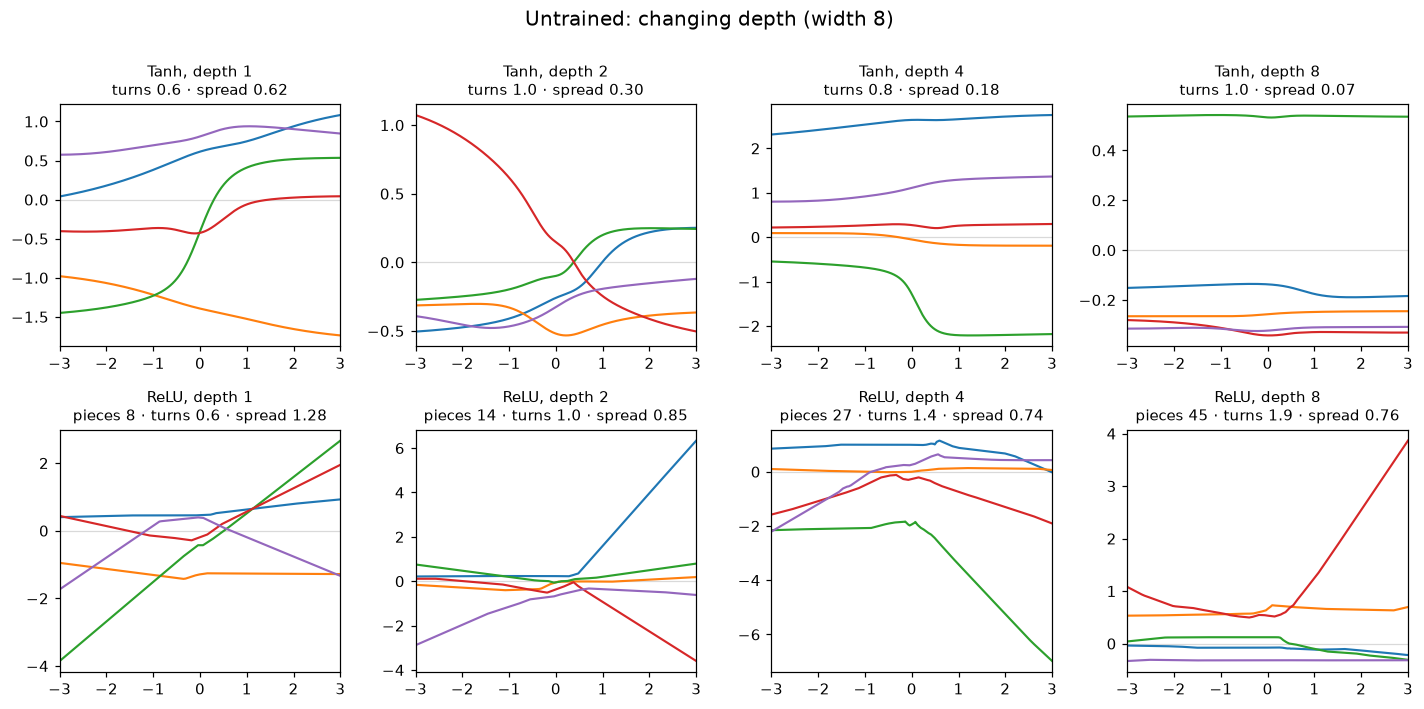

In [4]:
DEPTHS = [1, 2, 4, 8]
fig, axes = plt.subplots(2, 4, figsize=(13, 6.4))
for row, act in enumerate(["tanh", "relu"]):
    for ax, d in zip(axes[row], DEPTHS):
        untrained_panel(ax, d, 8, act, f"{NICE[act]}, depth {d}")
fig.suptitle("Untrained: changing depth (width 8)", fontsize=13, y=1.0)
plt.tight_layout(); plt.show()

**What to read here.**

- **ReLU: depth adds kinks and zig-zags.** Pieces grow from about 8 to 45, and visible turns roughly triple. A deeper ReLU network bends back and forth more.
- **Tanh: depth adds little shape, and the output shrinks.** Turning points stay around one, while the spread falls by almost 10× from depth 1 to 8 (at depth 8 the curves are nearly flat lines at different heights). With this initialization each tanh layer squeezes differences between inputs a bit, so a deep random tanh network partly "forgets" its input and its output is nearly constant. That's not more expressive. It's why the weight scale and initialization matter so much for deep networks.

## A2. Width: 2, 4, 8, 32 nodes per layer (depth 2)

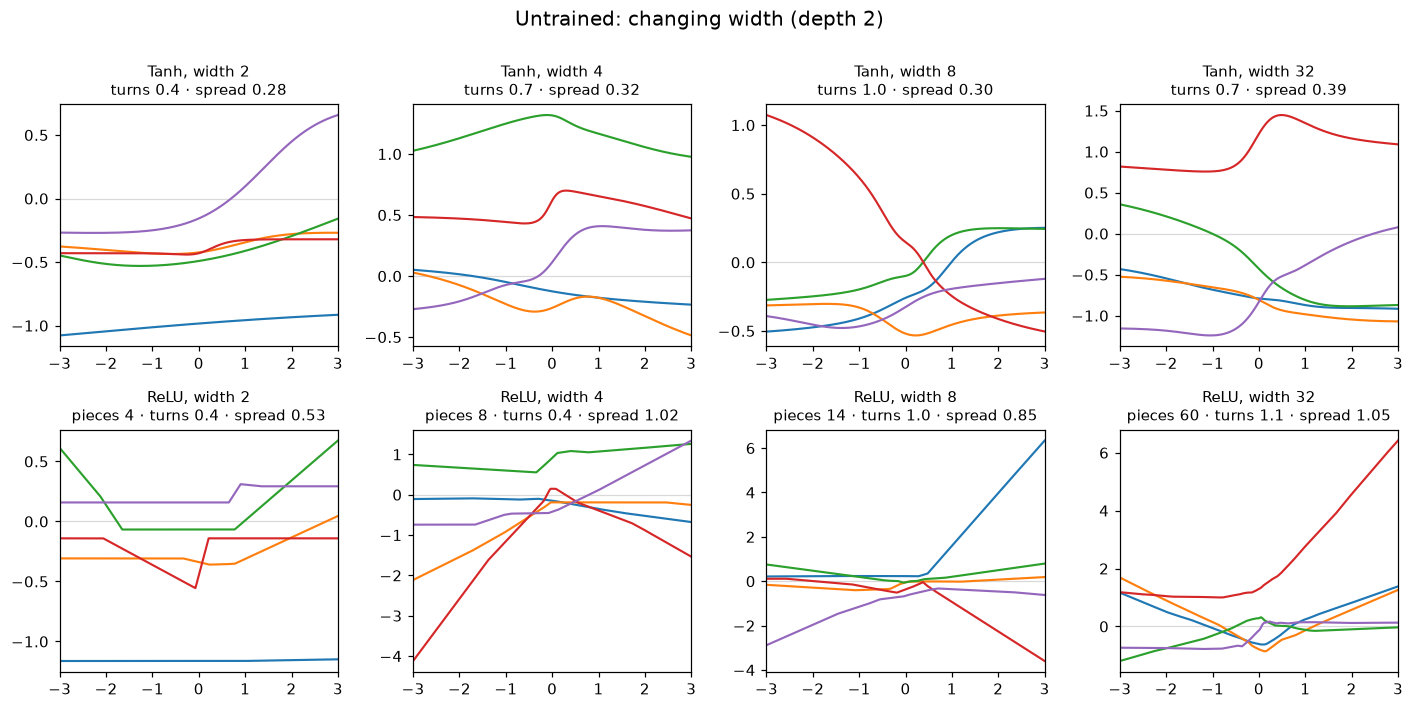

In [5]:
WIDTHS = [2, 4, 8, 32]
fig, axes = plt.subplots(2, 4, figsize=(13, 6.4))
for row, act in enumerate(["tanh", "relu"]):
    for ax, w in zip(axes[row], WIDTHS):
        untrained_panel(ax, 2, w, act, f"{NICE[act]}, width {w}")
fig.suptitle("Untrained: changing width (depth 2)", fontsize=13, y=1.0)
plt.tight_layout(); plt.show()

**What to read here.**

- **Very narrow networks are nearly monotone.** At width 2 there are only two nodes to combine per layer, so the curves are simple S-shapes or bends.
- **Tanh: extra width stops adding shape quickly.** Visible turns peak around width 8 and don't grow at width 32. The output is a sum of many random features scaled by $1/\sqrt{n}$, so as width grows it settles into a "typical" smooth random curve. (In the infinite-width limit the network becomes a *Gaussian process* — a known result.)
- **ReLU: width adds many pieces but fewer zig-zags than depth.** Pieces grow to about 60 at width 32 (more than the depth-8 network's 45), yet the curve visibly turns less often (about 1.1 vs. 1.9 times). Width adds *finer* kinks; depth adds *folds*.

## A3. Activation function (depth 2, width 8, identical weights)

All six panels use the **same random matrices $Z$** for each seed: same color, same weights (up to the gain $g$).

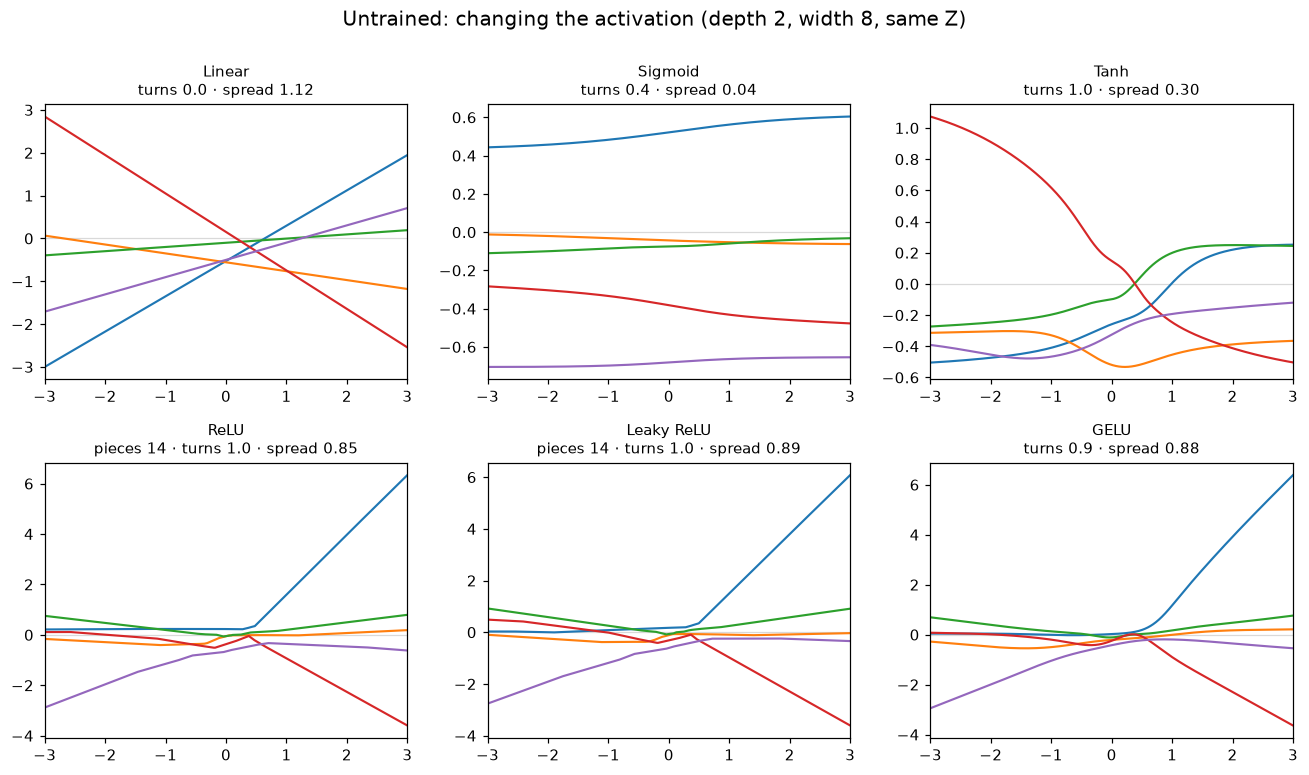

In [6]:
ACTS = ["linear", "sigmoid", "tanh", "relu", "leaky_relu", "gelu"]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, act in zip(axes.ravel(), ACTS):
    untrained_panel(ax, 2, 8, act, NICE[act])
fig.suptitle("Untrained: changing the activation (depth 2, width 8, same Z)", fontsize=13, y=1.0)
plt.tight_layout(); plt.show()

**What to read here.**

- **Linear collapses to a straight line**, whatever the depth or width: a chain of linear maps is one linear map.
- **Sigmoid is nearly flat** (spread about 0.04). Its outputs sit near 0.5 with slope only $\tfrac14$ at 0, so with this standard weight scale the signal hardly varies. That's one reason sigmoid fell out of favor for hidden layers ($\sigma(x) = \tfrac12\big(1+\tanh(x/2)\big)$, so it is a shifted, squashed tanh).
- **Tanh** gives smooth curves.
- **ReLU and Leaky ReLU** give almost the same piecewise-linear curves for the same seed. The small negative slope barely changes the forward pass.
- **GELU looks like a smoothed ReLU**: same seed, similar overall shape, but rounded corners. The activation decides the *texture* of the curve (straight, smooth, or kinked); the weights decide its overall layout.

## A4. Pieces and zig-zags vs. total neurons: depth or width?

To put depth and width on one axis, I plot ReLU measurements against the **total number of hidden neurons** — adding layers of 8 (depth sweep) versus widening two layers (width sweep).

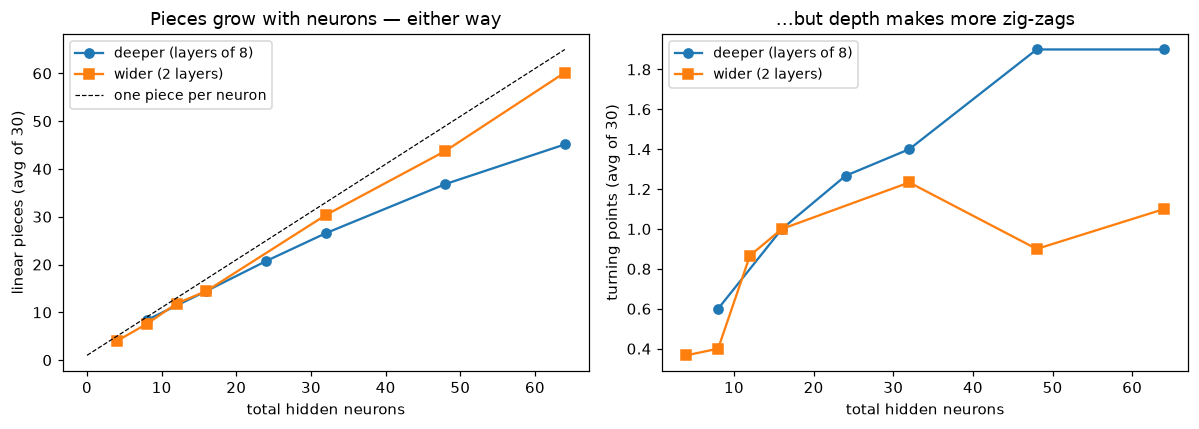

In [7]:
depth_cfg = [(d, 8) for d in (1, 2, 3, 4, 6, 8)]          # neurons = 8 d
width_cfg = [(2, w) for w in (2, 4, 6, 8, 16, 24, 32)]      # neurons = 2 w

def sweep(cfgs):
    neurons, pieces, turns = [], [], []
    for d, w in cfgs:
        st = summarize(d, w, "relu")
        neurons.append(d * w); pieces.append(st["pieces"]); turns.append(st["turns"])
    return np.array(neurons), np.array(pieces), np.array(turns)

nd, pd_, td = sweep(depth_cfg)
nw, pw, tw = sweep(width_cfg)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(nd, pd_, "o-", label="deeper (layers of 8)")
ax1.plot(nw, pw, "s-", label="wider (2 layers)")
ax1.plot([0, 64], [1, 65], "k--", lw=0.8, label="one piece per neuron")
ax1.set_xlabel("total hidden neurons"); ax1.set_ylabel("linear pieces (avg of 30)")
ax1.set_title("Pieces grow with neurons — either way"); ax1.legend(fontsize=9)
ax2.plot(nd, td, "o-", label="deeper (layers of 8)")
ax2.plot(nw, tw, "s-", label="wider (2 layers)")
ax2.set_xlabel("total hidden neurons"); ax2.set_ylabel("turning points (avg of 30)")
ax2.set_title("…but depth makes more zig-zags"); ax2.legend(fontsize=9)
plt.tight_layout(); plt.show()

**What to read here.** This is the most surprising result for me. In theory a deep ReLU network *can* make exponentially many pieces in its depth — far more than a shallow one with the same neurons. But **random** networks don't come close: the piece count is roughly **one per neuron**, whether the neurons are stacked or placed side by side (left). This matches published findings (Hanin & Rolnick, 2019). Depth's real difference at initialization is on the right: the same number of neurons produces **more turning points** when they're stacked, because each layer can fold the curve that the previous layer made. Whether training actually uses depth's extra potential is a question for part B.

## A5. Same parameter budget: shallow-wide vs. deep-narrow

Three ReLU networks with (almost) the same number of parameters:

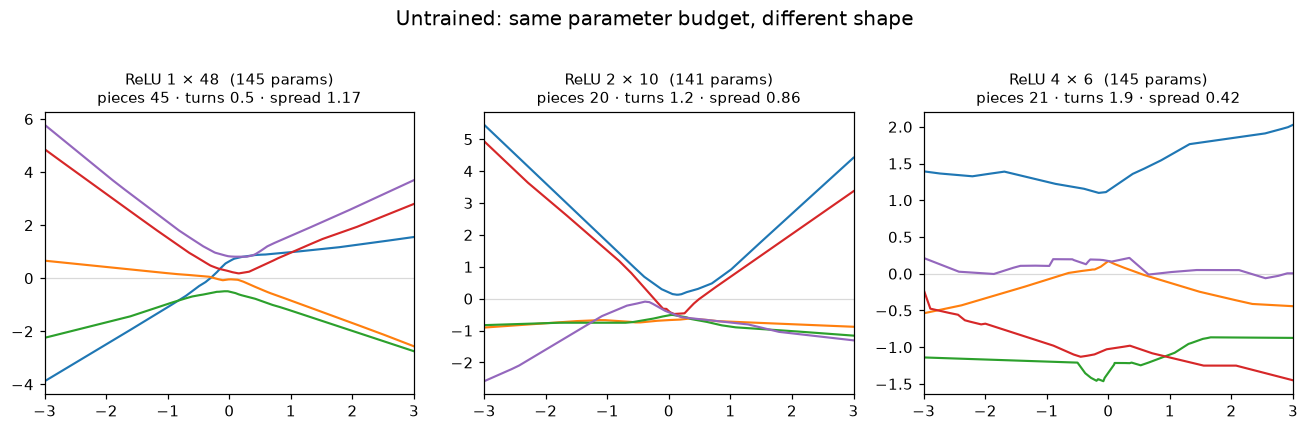

In [8]:
BUDGET = [(1, 48), (2, 10), (4, 6)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (d, w) in zip(axes, BUDGET):
    untrained_panel(ax, d, w, "relu", f"ReLU {d} × {w}  ({n_params(d, w)} params)")
fig.suptitle("Untrained: same parameter budget, different shape", fontsize=13, y=1.02)
plt.tight_layout(); plt.show()

**What to read here.** At the same budget, the shallow-wide network has the **most pieces** (one per neuron, and it has 48 neurons), but its curve is gentle. The deep-narrow network has fewer neurons and pieces, yet it **zig-zags the most**. Stacking spends parameters on *composition* (folding) rather than on more kinks.

# Part B — trained networks

Now the same architectures **learn** one curve. I train them with gradient descent, which needs the gradient of the loss with respect to every weight — computed by **backpropagation**. I haven't studied backpropagation yet, so for now the `loss_and_grads` function below is a black box (a later note will derive it). A numerical gradient check confirms it is correct.

**The task.** Fit the target

$$
f(x) = \sin(3x) + 0.5\,\lvert x\rvert \qquad \text{on } [-3, 3]
$$

from **50 noisy samples** $y = f(x) + \varepsilon$, $\varepsilon \sim \mathcal{N}(0, 0.1^2)$. The target has smooth waves (which suit smooth activations) and a sharp corner at $x = 0$ (which suits ReLU).

**Held fixed for every network:** the same 50 training points, mean squared error loss, the Adam optimizer (gradient descent with a per-parameter adaptive step), learning rate $0.01$, **3000** full-batch steps, and the initializations from part A (seeds 0–5).

- **Train MSE** is measured on the 50 noisy points.
- **Test MSE** compares the network to the *true* curve $f$ on a fine grid.
- The noise variance $0.1^2 = 0.01$ is the **noise floor**. A train MSE well below 0.01 means the network is fitting the noise (*overfitting*); a test MSE well above it means it missed the curve.

In [9]:
def loss_and_grads(params, x, y, act):
    """MSE loss and its gradient w.r.t. every W and b (backpropagation — black box for now)."""
    df = ACT[act][1]
    y_hat, cache = forward(params, x, act)
    loss = np.mean((y_hat - y) ** 2)
    delta = (2.0 / len(x)) * (y_hat - y)[:, None]           # dL/da for the output layer
    grads = [None] * len(params)
    for l in reversed(range(len(params))):
        W, _ = params[l]
        grads[l] = [delta.T @ cache[l][1], delta.sum(0)]
        if l > 0:
            delta = (delta @ W) * df(cache[l][0])           # pass dL/da back one layer
    return loss, grads

def train(params, x, y, act, steps=3000, lr=0.01, b1=0.9, b2=0.999, eps=1e-8):
    """Full-batch Adam. Returns the trained parameters and the loss history."""
    params = [[W.copy(), b.copy()] for W, b in params]
    m = [[np.zeros_like(p) for p in layer] for layer in params]
    v = [[np.zeros_like(p) for p in layer] for layer in params]
    history = []
    for t in range(1, steps + 1):
        loss, g = loss_and_grads(params, x, y, act)
        history.append(loss)
        for l in range(len(params)):
            for k in range(2):
                m[l][k] = b1 * m[l][k] + (1 - b1) * g[l][k]
                v[l][k] = b2 * v[l][k] + (1 - b2) * g[l][k] ** 2
                m_hat, v_hat = m[l][k] / (1 - b1**t), v[l][k] / (1 - b2**t)
                params[l][k] -= lr * m_hat / (np.sqrt(v_hat) + eps)
    return params, np.array(history)

# Gradient check: compare backprop with central finite differences on random entries.
rng = np.random.default_rng(0)
xc, yc = rng.uniform(-3, 3, 20), rng.standard_normal(20)
for act in ACT:
    p = init_params(3, 5, act, 1)
    _, g = loss_and_grads(p, xc, yc, act)
    worst = 0.0
    for l in range(len(p)):
        for k in range(2):
            P = p[l][k]; idx = np.unravel_index(rng.integers(P.size), P.shape); old = P[idx]
            P[idx] = old + 1e-6; lp, _ = loss_and_grads(p, xc, yc, act)
            P[idx] = old - 1e-6; lm, _ = loss_and_grads(p, xc, yc, act); P[idx] = old
            num = (lp - lm) / 2e-6
            worst = max(worst, abs(num - g[l][k][idx]) / (abs(num) + abs(g[l][k][idx]) + 1e-12))
    print(f"{NICE[act]:11s} max relative error {worst:.1e}")

Linear      max relative error 4.2e-09
Sigmoid     max relative error 5.6e-08
Tanh        max relative error 2.5e-09
ReLU        max relative error 1.2e-09
Leaky ReLU  max relative error 5.8e-08
GELU        max relative error 4.9e-08


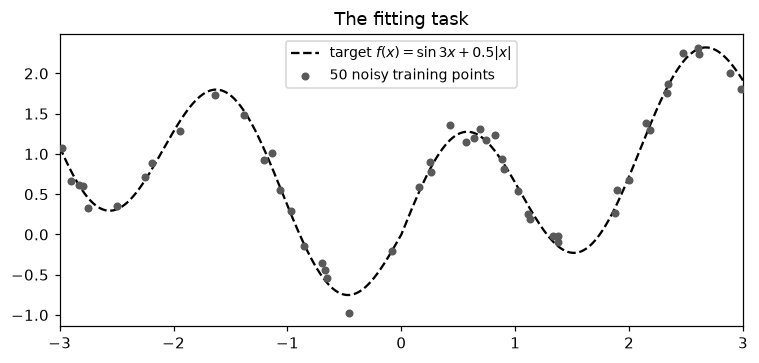

In [10]:
def target(x):
    return np.sin(3 * x) + 0.5 * np.abs(x)

rng = np.random.default_rng(0)
x_tr = np.sort(rng.uniform(-3, 3, 50))
y_tr = target(x_tr) + 0.1 * rng.standard_normal(50)
NOISE_FLOOR = 0.1 ** 2

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(X, target(X), "k--", lw=1.5, label=r"target $f(x) = \sin 3x + 0.5|x|$")
ax.scatter(x_tr, y_tr, s=18, color="0.35", zorder=3, label="50 noisy training points")
ax.set_xlim(-3, 3); ax.legend(fontsize=9, loc="upper center"); ax.set_title("The fitting task")
plt.tight_layout(); plt.show()

In [11]:
TRAIN_SEEDS = range(6)
RESULTS = {}

def fit(depth, width, act):
    """Train one architecture from each seed (cached). Test MSE is against the true curve."""
    key = (depth, width, act)
    if key not in RESULTS:
        runs = []
        for s in TRAIN_SEEDS:
            p, hist = train(init_params(depth, width, act, s), x_tr, y_tr, act)
            y_hat, _ = forward(p, X, act)
            runs.append(dict(params=p, hist=hist, curve=y_hat, train=hist[-1],
                             test=np.mean((y_hat - target(X)) ** 2)))
        RESULTS[key] = runs
    return RESULTS[key]

def show_trained(configs, labels, colors, title):
    """Top: the fitted curves (one thin line per seed). Bottom: loss curves and final errors."""
    runs = [fit(*c) for c in configs]
    n = len(configs); ncol = 3 if n in (3, 6) else min(n, 4); nrow = math.ceil(n / ncol)
    fig = plt.figure(figsize=(max(3.3 * ncol, 10), 2.9 * nrow + 3.5), layout="constrained")
    top, bottom = fig.subfigures(2, 1, height_ratios=[2.9 * nrow, 3.5])
    axes = np.atleast_1d(top.subplots(nrow, ncol, sharey=True)).ravel()
    for ax, r, lab, col in zip(axes, runs, labels, colors):
        ax.plot(X, target(X), "k--", lw=1.0)
        ax.scatter(x_tr, y_tr, s=8, color="0.55", zorder=3)
        for run in r:
            ax.plot(X, run["curve"], color=col, lw=1.1, alpha=0.75)
        ax.set_title(f"{lab}\ntest MSE {np.median([q['test'] for q in r]):.3f}", fontsize=10)
        ax.set_xlim(-3, 3); ax.set_ylim(-1.5, 3.0)
    for ax in axes[n:]:
        ax.axis("off")

    ax_l, ax_b = bottom.subplots(1, 2)
    for r, lab, col in zip(runs, labels, colors):
        ax_l.plot(np.median([q["hist"] for q in r], axis=0), color=col, lw=1.5, label=lab)
    ax_l.axhline(NOISE_FLOOR, color="k", ls=":", lw=1)
    ax_l.set_yscale("log"); ax_l.set_xlabel("training step"); ax_l.set_ylabel("train MSE (median)")
    ax_l.set_title("Training loss", fontsize=10); ax_l.legend(fontsize=8)

    pos = np.arange(n)
    for off, key, alpha, name in ((-0.2, "train", 0.45, "train"), (0.2, "test", 1.0, "test")):
        vals = np.array([[q[key] for q in r] for r in runs])
        med = np.median(vals, axis=1)
        err = np.vstack([med - vals.min(1), vals.max(1) - med])
        ax_b.bar(pos + off, med, width=0.4, color=colors, alpha=alpha, yerr=err, capsize=3,
                 edgecolor="k", linewidth=0.5, label=name)
    ax_b.axhline(NOISE_FLOOR, color="k", ls=":", lw=1, label="noise floor")
    ax_b.set_yscale("log"); ax_b.set_xticks(pos, labels, fontsize=8, rotation=15)
    ax_b.set_title("Final error (light = train, dark = test)\nmedian over seeds; whiskers = min–max",
                   fontsize=10)
    fig.suptitle(title, fontsize=13)
    plt.show()

def table(configs, labels):
    print(f"{'network':22s} {'params':>6s} {'train MSE':>10s} {'test MSE':>10s}")
    for c, lab in zip(configs, labels):
        r = fit(*c)
        print(f"{lab:22s} {n_params(c[0], c[1]):6d} {np.median([q['train'] for q in r]):10.4f}"
              f" {np.median([q['test'] for q in r]):10.4f}")

## B1. Depth (tanh, width 8)

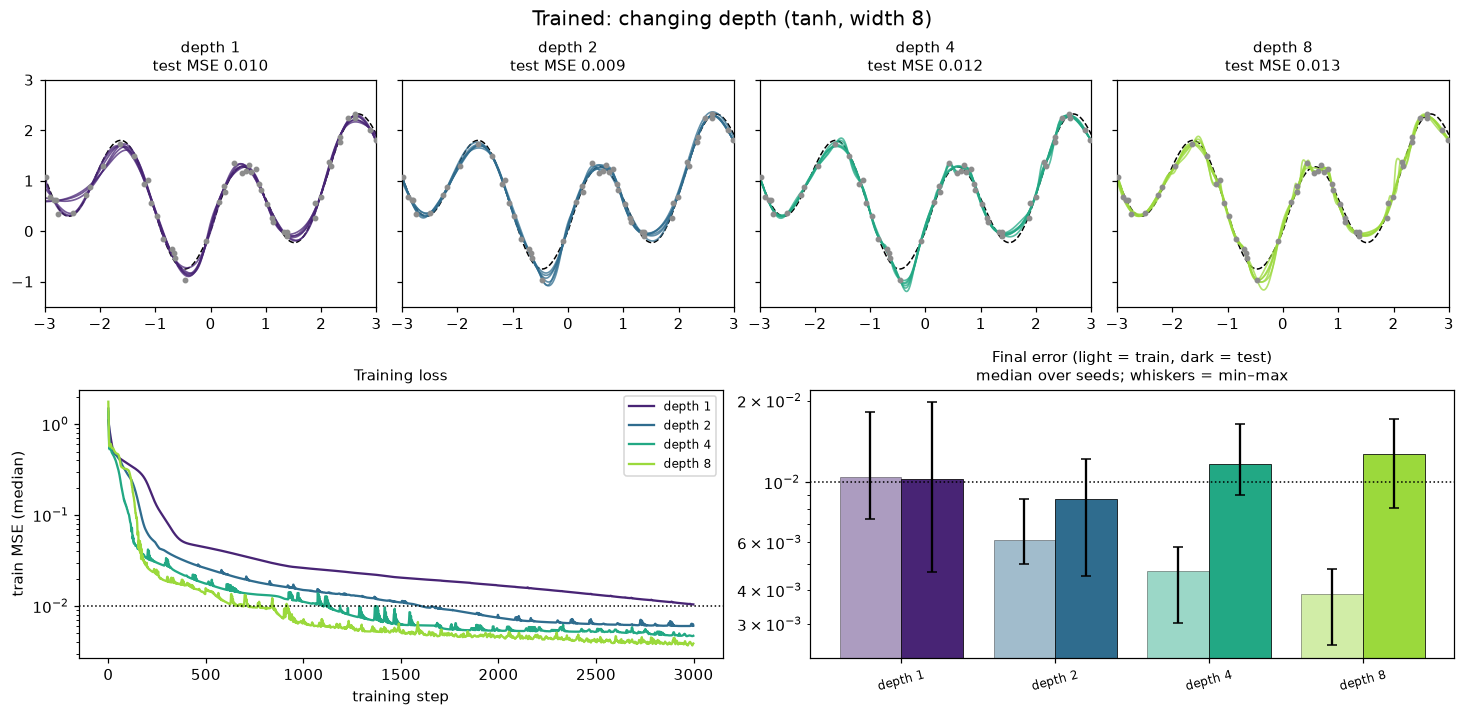

network                params  train MSE   test MSE
depth 1                    25     0.0104     0.0103
depth 2                    97     0.0061     0.0087
depth 4                   241     0.0047     0.0117
depth 8                   529     0.0039     0.0127


In [12]:
cfg = [(d, 8, "tanh") for d in DEPTHS]
lab = [f"depth {d}" for d in DEPTHS]
col = plt.cm.viridis(np.linspace(0.1, 0.85, len(cfg)))
show_trained(cfg, lab, col, "Trained: changing depth (tanh, width 8)")
table(cfg, lab)

**What to read here.** Going deeper keeps lowering the **training** error, from about the noise floor at depth 1 to well below it at depth 8 — and deeper networks also get there faster (training-loss panel). But the **test** error is best at depth 2 and creeps back up after that. The extra layers spend their capacity on the noise, as small wiggles between training points. On this task, one or two hidden layers are already enough. Also notice that depth trained fine even though the untrained deep tanh networks were nearly flat (A1): training quickly scales the weights up.

## B2. Width (tanh, depth 2)

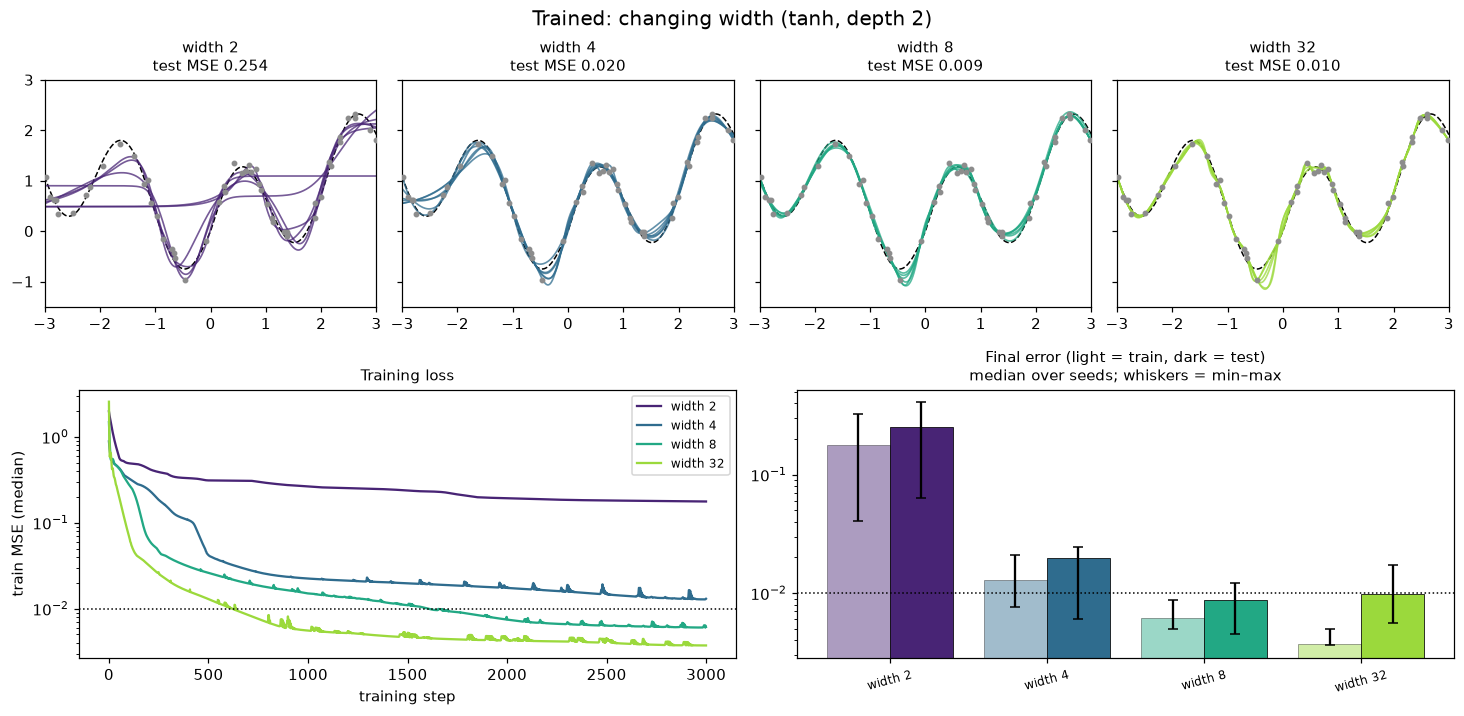

network                params  train MSE   test MSE
width 2                    13     0.1764     0.2544
width 4                    33     0.0130     0.0198
width 8                    97     0.0061     0.0087
width 32                 1153     0.0037     0.0099


In [13]:
cfg = [(2, w, "tanh") for w in WIDTHS]
lab = [f"width {w}" for w in WIDTHS]
col = plt.cm.viridis(np.linspace(0.1, 0.85, len(cfg)))
show_trained(cfg, lab, col, "Trained: changing width (tanh, depth 2)")
table(cfg, lab)

**What to read here.** Width 2 clearly **underfits**: there aren't enough nodes to make three waves and a corner, so its error stays far above the noise floor no matter how long it trains. Width 4 gets most of the way, and width 8 reaches the noise floor. Width 32 lowers the training error further but not the test error — the same diminishing returns as in B1. Width fixes underfitting, and then extra width mostly fits noise.

## B3. Activation function (depth 2, width 8)

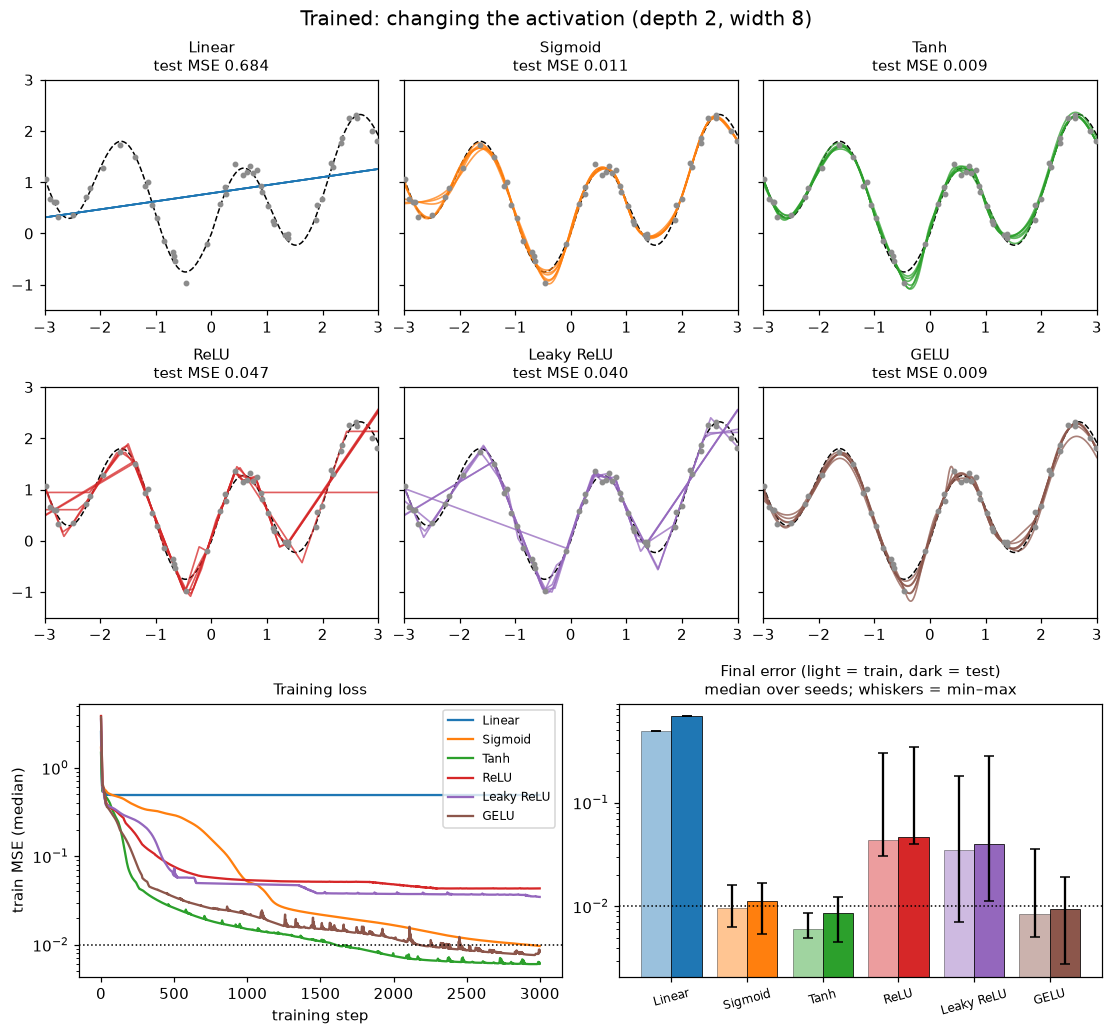

network                params  train MSE   test MSE
Linear                     97     0.4921     0.6835
Sigmoid                    97     0.0097     0.0112
Tanh                       97     0.0061     0.0087
ReLU                       97     0.0433     0.0471
Leaky ReLU                 97     0.0347     0.0401
GELU                       97     0.0084     0.0094


In [14]:
cfg = [(2, 8, a) for a in ACTS]
lab = [NICE[a] for a in ACTS]
col = [plt.cm.tab10(i) for i in range(len(cfg))]
show_trained(cfg, lab, col, "Trained: changing the activation (depth 2, width 8)")
table(cfg, lab)

**What to read here.**

- **Linear can only fit the best straight line**, so its error is huge. No amount of training adds curvature.
- **Smooth activations (sigmoid, tanh, GELU) fit this smooth target well** at width 8. Sigmoid trains fine here despite its nearly flat start (A3), because Adam's adaptive step size makes up for small gradients in a shallow network.
- **ReLU and Leaky ReLU do worse, with large differences between seeds.** With 8 nodes per layer they have only a dozen or so straight pieces to draw three smooth waves, and some seeds lose part of their nodes: a ReLU node whose input stays negative has zero gradient and stops learning (*dead ReLU*). Leaky ReLU's small slope helps a little.

The right activation depends on the target. Smooth activations fit smooth curves with fewer nodes; ReLU's strengths (cheap, no saturation, and trainable when very deep) matter more in large networks than in this small one.

## B4. Same parameter budget (ReLU): shallow-wide vs. deep-narrow

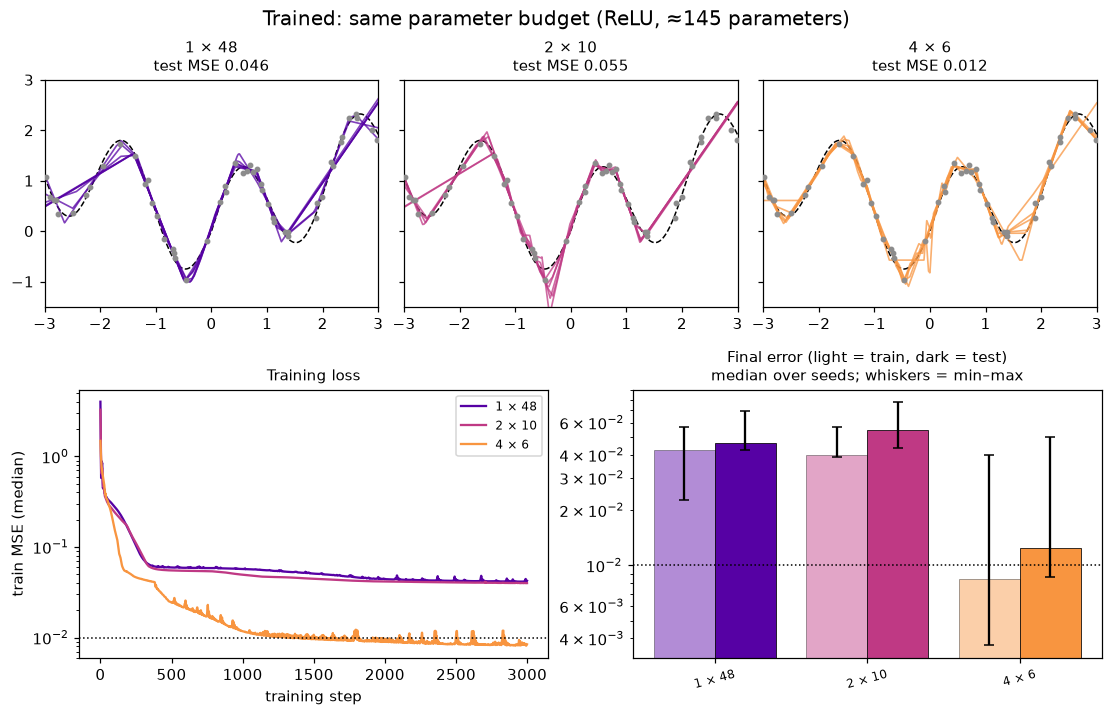

network                params  train MSE   test MSE
1 × 48                    145     0.0424     0.0462
2 × 10                    141     0.0399     0.0546
4 × 6                     145     0.0084     0.0125

linear pieces (median over seeds): before → after training
  1 × 48     45 →    43
  2 × 10     21 →    21
  4 × 6      23 →    30


In [15]:
cfg = [(d, w, "relu") for d, w in BUDGET]
lab = [f"{d} × {w}" for d, w in BUDGET]
col = plt.cm.plasma(np.linspace(0.15, 0.75, len(cfg)))
show_trained(cfg, lab, col, "Trained: same parameter budget (ReLU, ≈145 parameters)")
table(cfg, lab)

print("\nlinear pieces (median over seeds): before → after training")
for (d, w, a), name in zip(cfg, lab):
    before = np.median([count_pieces(init_params(d, w, a, s), a) for s in TRAIN_SEEDS])
    after = np.median([count_pieces(r["params"], a) for r in fit(d, w, a)])
    print(f"  {name:7s} {before:5.0f} → {after:5.0f}")

**What to read here.** This reverses part A. Untrained, the shallow 1 × 48 network had the most pieces (A5). After training on the same budget, the **deep-narrow 4 × 6 network fits best**, and training **increases** its piece count while the shallow network's stays about the same. My reading: the target repeats a similar bump several times, and a deep network can make one bump and then *fold* it into copies (that's what composition does), while a shallow network must build every kink separately. So depth's extra expressive power from A4 shows up once training uses it.

Two honest caveats. The shallow network didn't get better with more training — I checked 10,000 steps. One likely reason: its kinks start out bunched near $x = 0$, because the first-layer biases are small relative to the weights, and gradient descent struggles to spread them out. Also, the deep-narrow network varies more between seeds: narrow ReLU layers are easier to "kill" by dead nodes.

## Recap — a mental model

| Factor | Untrained (random weights) | Trained on one curve | Rule of thumb |
|---|---|---|---|
| **Depth** | ReLU: more zig-zags (folds). Tanh: output shrinks unless the init is tuned | lower training error, but extra depth fits noise here | depth = *composition*; it pays off when the target has repeated or hierarchical structure |
| **Width** | more pieces / features; shape settles quickly into a "typical" smooth curve | fixes underfitting, then diminishing returns | make it wide enough not to underfit, not much more |
| **Activation** | sets the *texture*: straight (linear), smooth (sigmoid/tanh/GELU), kinked (ReLU) | linear can't fit curves; smooth suits smooth targets with few nodes; ReLU needs more nodes | non-linearity is essential; ReLU/GELU are the defaults for large networks |
| **Budget split** | shallow-wide: more pieces; deep-narrow: more folds | deep-narrow fitted this repetitive target best | at a fixed size, depth is often the better use of parameters (but narrow ReLU layers are fragile) |

**Caveats I want to remember**

- One target, 50 points, 1D input, and one fixed training recipe. A different learning rate or step count could change the rankings for some networks, especially the ones that were still improving.
- The untrained results depend on the initialization (gain $g$, bias scale $0.5$). Deep tanh networks, for example, behave very differently with other weight scales.
- "Turning points" and "pieces" are crude measures of complexity, and 6 seeds is a small sample, so read the spreads (min–max bars), not just the medians.

## Acknowledgment

This study accompanies my notes for **24-887 — Machine Learning & Artificial Intelligence for Engineers**, taught by Professor Levent Burak Kara as part of Carnegie Mellon University's [AI Engineering Fundamentals](https://www.cmu.edu/online/ai-engineering-fundamentals) graduate certificate. Credit for the course material goes to the instructor and CMU; the experiments and any errors here are my own.